# IMF Country Report to Dashboard Pipeline: South Korea (2022-2023)

**What this notebook does**

1. Reads the IMF PDF, cleans it and splits it into 400 token chunks with 50 token overlap
2. Summarises every section (under 100 words), writes an executive summary, and a second model (the judge) scores each summary
3. Counts 7 financial stability themes, extracts strengths and vulnerabilities, and extracts the core indicators into a JSON file with fallbacks
4. Builds a local RAG index (sentence-transformers + FAISS) and tests it with factual questions
5. Reshapes the data with `pd.melt` and draws a 4 panel dashboard (300 dpi)
6. Extension: compares two Gemini Flash variants on schema compliance, latency, coverage and judge accuracy


In [1]:
!pip -q install pypdf sentence-transformers faiss-cpu google-genai tiktoken

## 0. Settings and helper functions

In [2]:
import os, re, json, time, hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google import genai
from google.genai import types

# Google Drive keeps the cache and outputs safe even if Colab disconnects
from google.colab import drive
drive.mount("/content/drive")

# ---- settings you may want to change ----
PDF_PATH    = "/content/drive/MyDrive/null-002.2022.issue-086-en.pdf"
BASE_DIR    = "/content/drive/MyDrive/imf_korea_project"
OUT_DIR     = f"{BASE_DIR}/outputs"       # json files and the dashboard
CACHE_DIR   = f"{BASE_DIR}/cache"         # every LLM answer is saved here as soon as it arrives
GEN_MODEL   = "gemini-3.8-flash"          # writes summaries and extracts
JUDGE_MODEL = "gemini-3.5-flash"          # only audits
ALT_MODEL   = "gemini-3.5-flash-lite"     # second variant for the extension comparison only
PAUSE_SECONDS = 13                        # 5 requests per minute allowed, so one new call every 13 seconds is safe
MAX_CHARS = 150000                        # longest text sent to a model in one prompt
TRIAL_SECTIONS = None                     # set to 2 for a cheap test on two sections, then back to None
LAST_ACTUAL_YEAR = 2021                   # last year with actual (not projected) data in the report, check its indicators table

assert GEN_MODEL != JUDGE_MODEL, "The generator and the judge must be different models"

os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)

API_KEY = None
for name in ["GEMINI_API_KEY"]:          # the secret can have either name
    try:
        from google.colab import userdata
        API_KEY = userdata.get(name)
    except Exception:
        API_KEY = os.environ.get(name)
    if API_KEY:
        break
assert API_KEY, "No API key found. Add a Colab secret called GEMINI_API_KEY and switch notebook access on."
client = genai.Client(api_key=API_KEY)

Mounted at /content/drive


In [3]:
MODEL_LOG = Counter()     # counts how many answers each model gave (cache hits included)

def call_llm(prompt, model=GEN_MODEL, system=None, as_json=False):
    """Send one prompt to ONE model and return {"text", "latency", "model_used"}.
    - No fallback models: if the model is busy or over quota we wait and retry the same model.
    - Every good answer is written to Drive straight away, so a re-run costs nothing for finished calls.
    - Empty answers are never saved."""
    key = hashlib.sha256(json.dumps([model, system, prompt, as_json]).encode()).hexdigest()
    path = f"{CACHE_DIR}/{key}.json"
    if os.path.exists(path):
        try:
            with open(path) as f:
                result = json.load(f)
            MODEL_LOG[result["model_used"]] += 1
            return result
        except Exception:
            pass                                     # damaged cache file, ask again

    config = types.GenerateContentConfig(
        system_instruction=system, temperature=0.0,
        response_mime_type="application/json" if as_json else "text/plain")

    for attempt in range(6):
        try:
            start = time.time()
            reply = client.models.generate_content(model=model, contents=prompt, config=config)
            text = reply.text or ""
            if not text.strip():
                raise ValueError("empty reply")
            result = {"text": text, "latency": round(time.time() - start, 2), "model_used": model}
            with open(path + ".tmp", "w") as f:      # write to a temp file first, then rename
                json.dump(result, f)
            os.replace(path + ".tmp", path)
            MODEL_LOG[model] += 1
            time.sleep(PAUSE_SECONDS)
            return result
        except Exception as e:
            msg = str(e)
            if "404" in msg or "NOT_FOUND" in msg:
                raise RuntimeError(f"Model '{model}' is not available for this key. Change the name in the settings cell.")
            if "PerDay" in msg or "per day" in msg.lower():     # daily limit: waiting a minute will not help
                raise RuntimeError(f"{model} daily limit reached. Everything finished so far is saved, run this cell again tomorrow.")
            quota = "429" in msg or "RESOURCE_EXHAUSTED" in msg
            wait = 60 if quota else min(15 * 2 ** attempt, 120)
            print(f"{model} {'quota limit' if quota else 'busy'} ({msg[:40]}), waiting {wait}s, try {attempt+1} of 6")
            time.sleep(wait)
    raise RuntimeError(f"{model} could not answer. Wait a few minutes and re-run this cell, finished calls are already saved.")

def parse_json(text):
    """Turn model output into a Python object. Returns None if the JSON is broken."""
    text = re.sub(r"^```(?:json)?|```$", "", text.strip(), flags=re.M).strip()
    try:
        return json.loads(text)
    except Exception:
        return None

def save_json(obj, name):
    with open(f"{OUT_DIR}/{name}", "w") as f:
        json.dump(obj, f, indent=2)

## 1. Task 1: Load the PDF, clean the text, chunk it

Cleaning choices:
- Lines that repeat on many pages (running headers and footers) are found automatically and dropped
- Bare page numbers are dropped, hyphenated line breaks are joined, and line breaks become spaces
- Sections are found in three steps: PDF bookmarks first, then ALL CAPS headings, then 8 equal parts as a last resort

In [4]:
from pypdf import PdfReader

if not os.path.exists(PDF_PATH):
    raise FileNotFoundError(f"PDF not found at {PDF_PATH}. Check the path in the settings cell.")

reader = PdfReader(PDF_PATH)
pages = [p.extract_text() or "" for p in reader.pages]
print("pages read:", len(pages), "| raw characters:", sum(len(p) for p in pages))

pages read: 87 | raw characters: 189924


In [5]:
# find lines that show up on at least 30% of pages (headers and footers)
page_lines = [[l.strip() for l in p.split("\n") if l.strip()] for p in pages]
line_counts = Counter(l for pl in page_lines for l in set(pl))
repeated = {l for l, c in line_counts.items() if c >= max(3, 0.3 * len(pages)) and len(l) < 100}
print("header/footer lines removed:", list(repeated)[:5])

def is_heading(line):
    return line.isupper() and 6 <= len(line) <= 70 and not any(ch.isdigit() for ch in line)

def tidy(t):
    t = re.sub(r"(\w)- (\w)", r"\1\2", t)       # join hyphenated line breaks
    return re.sub(r"\s+", " ", t).strip()

def strip_marks(t):
    return re.sub(r"@@HEAD@@ (.+?) @@END@@", r"\1.", t)

# one cleaned string per page; ALL CAPS lines are marked as possible headings
page_text = []
for pl in page_lines:
    keep = []
    for l in pl:
        if l in repeated or re.fullmatch(r"\d{1,3}", l):
            continue
        keep.append(f"@@HEAD@@ {l} @@END@@" if is_heading(l) else l)
    page_text.append(" ".join(keep))

full = tidy(" ".join(page_text))
text_clean = strip_marks(full)
print("clean words:", len(text_clean.split()))

header/footer lines removed: ['REPUBLIC OF KOREA']
clean words: 27544


In [6]:
def merge_short(secs, min_words=150, max_sections=8):
    """Merge tiny sections into the previous one, then merge the smallest until at most max_sections remain."""
    out = []
    for t, b in secs:
        if out and len(b.split()) < min_words:
            out[-1][1] += f" {t}. {b}"
        else:
            out.append([t, b])
    while len(out) > max_sections:
        i = min(range(1, len(out)), key=lambda j: len(out[j][1].split()))
        out[i-1][1] += f" {out[i][0]}. {out[i][1]}"
        del out[i]
    return out

def sections_from_outline():
    """Use the PDF bookmarks (if the file has them) as chapter starts."""
    starts = []
    try:
        for item in reader.outline:
            if isinstance(item, list):
                continue
            starts.append((reader.get_destination_page_number(item), str(item.title)))
    except Exception:
        return []
    starts = sorted(set(s for s in starts if s[0] is not None))
    secs = []
    for n, (p, t) in enumerate(starts):
        end = starts[n+1][0] if n + 1 < len(starts) else len(page_text)
        secs.append([t, tidy(strip_marks(" ".join(page_text[p:max(end, p+1)])))])
    return secs

def sections_from_headings():
    """Use the ALL CAPS lines marked earlier as headings."""
    parts = re.split(r"@@HEAD@@ (.+?) @@END@@", full)
    pairs = [("Introduction", parts[0])] + list(zip(parts[1::2], parts[2::2]))
    return [[t.title(), b] for t, b in pairs]

def equal_parts(n=8):
    words = text_clean.split()
    size = len(words) // n + 1
    return [[f"Part {i+1}", " ".join(words[i*size:(i+1)*size])] for i in range(n)]

def sections_ok(secs):
    """Accept a split only if it has 5 to 12 sections and none holds more than 35% of the words."""
    if not 5 <= len(secs) <= 12:
        return False
    sizes = [len(b.split()) for _, b in secs]
    return max(sizes) <= 0.35 * sum(sizes)

sections, method = merge_short(sections_from_outline()), "PDF bookmarks"
if not sections_ok(sections):
    sections, method = merge_short(sections_from_headings()), "ALL CAPS headings"
if not sections_ok(sections):
    sections, method = equal_parts(), "8 equal parts (no usable headings found)"

print("section method:", method)
for t, b in sections:
    flag = "  (longer than MAX_CHARS, tail is not summarised)" if len(b) > MAX_CHARS else ""
    print(f"{t[:50]:50s} {len(b.split()):6d} words{flag}")

section method: ALL CAPS headings
Introduction                                          285 words
For Immediate Release                                2036 words
Recent Economic Developments                         1498 words
Outlook And Risks                                    1417 words
Policy Discussion                                    8259 words
Staff Appraisal                                      9004 words
Fsc/Fss                                               961 words
Statistical Issues                                   4068 words


In [7]:
import tiktoken
enc = tiktoken.get_encoding("cl100k_base")

def chunk_text(text, size=400, overlap=50):
    """Cut text into windows of `size` tokens that share `overlap` tokens with the previous one."""
    ids = enc.encode(text)
    chunks = []
    for start in range(0, len(ids), size - overlap):
        chunks.append(enc.decode(ids[start:start + size]))
        if start + size >= len(ids):
            break
    return chunks

chunks = chunk_text(text_clean)
print("chunks:", len(chunks), "| first chunk tokens:", len(enc.encode(chunks[0])))

chunks: 113 | first chunk tokens: 400


## 2. Task 3 setup: local vector index plus keyword search (built early because later steps use it)

`all-MiniLM-L6-v2` makes the embeddings on the Colab machine and FAISS `IndexFlatL2` does the search. A plain keyword search is added next to it, because a small embedding model often misses table rows such as "Unemployment rate".

In [8]:
import faiss
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("all-MiniLM-L6-v2")
embedder.max_seq_length = 512      # default is 256, which would cut our 400 token chunks

emb = embedder.encode(chunks, convert_to_numpy=True, show_progress_bar=False).astype("float32")
index = faiss.IndexFlatL2(emb.shape[1])
index.add(emb)
print("vectors in index:", index.ntotal, "| dimension:", emb.shape[1])

def retrieve(query, k=4):
    """Return the k chunks closest to the query (smaller L2 distance = closer)."""
    q = embedder.encode([query], convert_to_numpy=True).astype("float32")
    dist, idx = index.search(q, k)
    return [chunks[i] for i in idx[0]], dist[0]

def keyword_chunks(pattern, max_chunks=5):
    """Chunks that literally contain the pattern. Chunks with many decimal numbers come first,
    because table rows (the numbers we want) matter more than narrative mentions."""
    hits = [c for c in chunks if re.search(pattern, c, re.I)]
    hits.sort(key=lambda c: len(re.findall(r"\d+\.\d", c)), reverse=True)
    return hits[:max_chunks]

def context_for(queries, k=3, patterns=()):
    """Unique chunks from vector search (per query) and keyword search (per pattern), joined into one context."""
    seen, out = set(), []
    found = [c for q in queries for c in retrieve(q, k)[0]] + [c for p in patterns for c in keyword_chunks(p)]
    for c in found:
        if c not in seen:
            seen.add(c)
            out.append(c)
    return "\n\n---\n\n".join(out)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

vectors in index: 113 | dimension: 384


## 3. Task 1: Section summaries, executive summary and the judge loop

For each section: summarise, check the word count in Python, let the judge score it (1 to 5 on consistency, completeness, factual alignment), and if any score is below 4 ask for one revision using the judge's comment. The judge is told to list missing points before scoring, and the notebook records which model generated and which model judged, so you can see if they were the same.

In [9]:
SUM_SYSTEM = ("You are a financial stability analyst. Use only the text you are given. "
              "Never add numbers or facts that are not in the text.")
JUDGE_SYSTEM = ("You are a strict auditor of financial summaries. Compare the summary with the source text only. "
                "Do not use outside knowledge. Return JSON only.")

def summarise_section(title, text, feedback=""):
    """Returns (summary, model that wrote it). Stops with an error if it cannot get under 100 words."""
    prompt = ("Summarise this section of an IMF report in fewer than 100 words, as one plain paragraph. "
              "Keep the main finding, key numbers and any risk judgement.\n"
              f"{feedback}\n\nSECTION: {title}\n\n{text}")
    for attempt in range(2):
        r = call_llm(prompt, GEN_MODEL, SUM_SYSTEM)
        s = r["text"].strip()
        if len(s.split()) < 100:                     # word limit checked in code, not trusted to the model
            return s, r["model_used"]
        prompt = ("Rewrite the following summary in fewer than 90 words. "
                  f"Keep all important findings, numbers and risk judgements.\n\n{s}")
    raise ValueError(f"Could not get a summary under 100 words for: {title}")

def judge_summary(source, summary):
    """Returns (scores dict or None if the judge reply is invalid, model that judged)."""
    prompt = f"""Score the SUMMARY against the SOURCE from 1 (bad) to 5 (excellent).
First list up to 3 important points from the SOURCE that the summary leaves out. Be strict: give 5 only when nothing important is missing.
consistency: no contradictions with the source
completeness: covers the main points of the source
factual_alignment: every number and claim in the summary appears in the source

Return JSON only:
{{"missing_points": ["..."], "consistency": 1, "completeness": 1, "factual_alignment": 1, "comment": "one sentence"}}

SOURCE:
{source}

SUMMARY:
{summary}"""
    resp = call_llm(prompt, JUDGE_MODEL, JUDGE_SYSTEM, as_json=True)
    r = parse_json(resp["text"])
    if not isinstance(r, dict) or not isinstance(r.get("comment"), str):
        return None, resp["model_used"]
    for k in ["consistency", "completeness", "factual_alignment"]:
        v = r.get(k)
        if isinstance(v, bool) or not isinstance(v, int) or not 1 <= v <= 5:
            return None, resp["model_used"]
    return r, resp["model_used"]

EMPTY_SCORE = {"consistency": None, "completeness": None, "factual_alignment": None,
               "comment": "Judge response could not be validated", "missing_points": []}

section_results = []
for title, body in (sections[:TRIAL_SECTIONS] if TRIAL_SECTIONS else sections):
    print("Processing:", title)
    source = body[:MAX_CHARS]                         # same text goes to the writer and the judge
    summary, gen_model = summarise_section(title, source)
    score, judge_model = judge_summary(source, summary)
    revised = False
    first_scores = None if score is None else {k: score[k] for k in ["consistency", "completeness", "factual_alignment"]}
    if score is None:
        score = dict(EMPTY_SCORE)
    elif min(score["consistency"], score["completeness"], score["factual_alignment"]) < 4:
        summary, gen_model = summarise_section(title, source,
            feedback=f"Fix this problem found by a reviewer: {score['comment']} Missing points: {score.get('missing_points')}. Keep the facts accurate.")
        new_score, judge_model = judge_summary(source, summary)
        score = new_score if new_score is not None else dict(EMPTY_SCORE)
        revised = True
    section_results.append({"section": title, "words": len(summary.split()), "summary": summary,
                            "revised_after_judge": revised, "first_pass_scores": first_scores, "generated_by": gen_model, "judged_by": judge_model,
                            "same_model_judged": gen_model == judge_model, **score})

sec_df = pd.DataFrame(section_results)
show_cols = ["section", "words", "consistency", "completeness", "factual_alignment", "revised_after_judge", "generated_by", "judged_by"]
print(sec_df[show_cols].to_string())
print("\nmean judge scores:\n", sec_df[["consistency", "completeness", "factual_alignment"]].astype(float).mean().round(2))
print("summaries judged by the same model that wrote them:", int(sec_df["same_model_judged"].sum()), "of", len(sec_df))
for _, r in sec_df[sec_df["revised_after_judge"]].iterrows():
    print("revised:", r["section"], "| first pass", r["first_pass_scores"], "| after revision", r["consistency"], r["completeness"], r["factual_alignment"])
truncated = [t for t, b in sections if len(b) > MAX_CHARS]
print("sections truncated at MAX_CHARS:", truncated if truncated else "none")

Processing: Introduction
Processing: For Immediate Release
Processing: Recent Economic Developments
Processing: Outlook And Risks
Processing: Policy Discussion
Processing: Staff Appraisal
Processing: Fsc/Fss
Processing: Statistical Issues
                        section  words  consistency  completeness  factual_alignment  revised_after_judge      generated_by         judged_by
0                  Introduction     90            5             5                  5                False  gemini-3.8-flash  gemini-3.5-flash
1         For Immediate Release     93            5             5                  5                 True  gemini-3.8-flash  gemini-3.5-flash
2  Recent Economic Developments     92            5             4                  5                False  gemini-3.8-flash  gemini-3.5-flash
3             Outlook And Risks     95            5             4                  5                False  gemini-3.8-flash  gemini-3.5-flash
4             Policy Discussion     93            5

In [10]:
assert not TRIAL_SECTIONS, "Trial run finished. Set TRIAL_SECTIONS = None in the settings cell and run again for the full report."
# executive summary built from the section summaries (map-reduce style)
joined = "\n".join(f"- {r['section']}: {r['summary']}" for r in section_results)
exec_prompt = f"""Using only the section summaries below, write 6 to 8 bullet points that give the main financial stability
findings and risk assessments of the whole report. Each bullet must be one sentence. Start each bullet with "- ".

{joined}"""
exec_resp = call_llm(exec_prompt, GEN_MODEL, SUM_SYSTEM)
exec_summary = exec_resp["text"].strip()
exec_source = "\n\n".join(b[:MAX_CHARS] for _, b in sections)[:500000]   # same text the section writers saw
exec_score, exec_judge = judge_summary(exec_source, exec_summary)
print(exec_summary)
print("\njudge:", exec_score, "| written by", exec_resp["model_used"], "| judged by", exec_judge)

save_json({"executive_summary": exec_summary, "executive_summary_judge": exec_score,
           "sections": section_results, "truncated_sections": truncated}, "summaries.json")

- Korea’s financial system remains sound with resilient banks, though borrower-based macroprudential measures may need further tightening to contain risks.
- Elevated household debt is very high and real estate prices are in overvaluation territory, posing significant domestic macro-financial vulnerabilities.
- Market risk sentiment may be turning, and many small and medium-sized enterprises remain vulnerable to the withdrawal of support.
- Economic risks are tilted to the downside due to global monetary normalization, geopolitical uncertainties, Omicron, and elevated domestic debt and real estate prices, while upside inflation risks heighten the threat of stagflationary pressures.
- Addressing inflation and financial imbalances, the Bank of Korea raised its policy rate by 75 basis points from 0.5 percent to pre-pandemic levels.
- Public debt is projected to increase to 60 percent of GDP by 2027 due to demographic aging and spending pressures, requiring a rules-based fiscal framework a

## 4. Task 2: Theme distribution

Step 1 is a transparent keyword count: each theme has a small keyword list, and we count matches over the full cleaned text and the number of chunks that contain at least one keyword. Step 4b then classifies the chunks with a model and compares the two.

In [11]:
THEMES = {
    "Inflation & Prices":        [r"\binflation", r"\bcpi\b", r"\bdisinflation", r"\bprice"],
    "Interest Rates & Credit":   [r"interest rate", r"policy rate", r"base rate", r"\bcredit", r"\blending", r"\bloans?\b"],
    "Housing & Real Estate":     [r"\bhousing", r"real estate", r"\bproperty", r"\bmortgage", r"\bjeonse", r"\bpf\b", r"project financing"],
    "Banking Capital & Liquidity": [r"\bcapital adequacy", r"\bcapital buffer", r"\bcapital ratio", r"\bliquidity", r"\bbanks?\b", r"\bprovisioning"],
    "Sovereign Debt":            [r"public debt", r"government debt", r"sovereign", r"\bfiscal", r"\bdeficit", r"\bbonds?\b"],
    "Labor Market Dynamics":     [r"\bunemployment", r"\blabou?r", r"\bemployment", r"\bwages?\b", r"\bworkers?\b"],
    "Systemic Financial Risk":   [r"\bsystemic", r"\bstress test", r"\bfinancial stability", r"\bcontagion", r"\bvulnerabilit", r"\bshock"],
}

low = text_clean.lower()
theme_counts, theme_chunk_cover, kw_sets = {}, {}, {}
for theme, patterns in THEMES.items():
    theme_counts[theme] = sum(len(re.findall(p, low)) for p in patterns)
    kw_sets[theme] = {i for i, c in enumerate(chunks) if any(re.search(p, c.lower()) for p in patterns)}
    theme_chunk_cover[theme] = len(kw_sets[theme])

theme_df = pd.DataFrame({"mentions": theme_counts, "chunks_covered": theme_chunk_cover})
theme_df["share_pct"] = (100 * theme_df["mentions"] / theme_df["mentions"].sum()).round(1)
print(theme_df.sort_values("mentions", ascending=False))
save_json({"counts": theme_counts, "chunks_covered": theme_chunk_cover,
           "total_chunks": len(chunks)}, "themes.json")

                             mentions  chunks_covered  share_pct
Inflation & Prices                243              69       25.1
Sovereign Debt                    170              57       17.6
Interest Rates & Credit           146              57       15.1
Housing & Real Estate             122              41       12.6
Labor Market Dynamics             115              32       11.9
Systemic Financial Risk            92              42        9.5
Banking Capital & Liquidity        79              37        8.2


## 4b. Task 2: Semantic theme classification (Gemini) and comparison with the keyword counts

Keyword counting misses passages that discuss a theme without its usual words, and counts words like "price" in other contexts. So every chunk is also classified by a model into 0 to 3 of the 7 themes (multi-label, 8 chunks per call). This uses `ALT_MODEL` (Flash-Lite, 500 calls a day), which is neither the generator nor the judge. The main measure of how widely a theme is discussed is the **number of chunks** that discuss it. Because a chunk can belong to several themes, the shares are shares of theme assignments, not exclusive parts of the report.

In [13]:
THEME_NAMES = list(THEMES.keys())
theme_list = "; ".join(THEME_NAMES)
BATCH = 8

def classify_batch(batch):
    """batch is a list of (chunk id, text). Returns {chunk id: [theme names]}."""
    items = "\n\n".join(f"[{i}] {c}" for i, c in batch)
    prompt = f"""Assign each numbered passage from an IMF report to every theme it substantially discusses (0 to 3 themes, empty list if none).
Themes: {theme_list}
A passage can discuss a theme without using its usual keywords, for example tighter borrower limits and financial imbalances belong to Systemic Financial Risk.
Return JSON only: {{"results": [{{"id": 0, "themes": ["theme name exactly as written"]}}]}}

PASSAGES:
{items}"""
    r = parse_json(call_llm(prompt, ALT_MODEL, "You classify passages of IMF reports into themes. Return JSON only.", as_json=True)["text"])
    out = {}

    # Handle cases where the model returns a list directly or a dictionary
    results = []
    if isinstance(r, dict):
        results = r.get("results", [])
    elif isinstance(r, list):
        results = r

    for row in results:
        if isinstance(row, dict) and isinstance(row.get("id"), int):
            out[row["id"]] = [t for t in row.get("themes", []) if t in THEME_NAMES]
    return out

semantic = {}
for start in range(0, len(chunks), BATCH):
    batch = [(i, chunks[i]) for i in range(start, min(start + BATCH, len(chunks)))]
    semantic.update(classify_batch(batch))
print("chunks classified:", len(semantic), "of", len(chunks))

sem_sets = {t: {i for i, ts in semantic.items() if t in ts} for t in THEME_NAMES}
theme_cmp = pd.DataFrame({
    "keyword_chunks":  {t: len(kw_sets[t]) for t in THEME_NAMES},
    "semantic_chunks": {t: len(sem_sets[t]) for t in THEME_NAMES},
    "both":            {t: len(kw_sets[t] & sem_sets[t]) for t in THEME_NAMES},
    "keyword_only":    {t: len(kw_sets[t] - sem_sets[t]) for t in THEME_NAMES},
    "semantic_only":   {t: len(sem_sets[t] - kw_sets[t]) for t in THEME_NAMES},
})
theme_cmp["semantic_share_pct"] = (100 * theme_cmp["semantic_chunks"] / theme_cmp["semantic_chunks"].sum()).round(1)
print(theme_cmp.sort_values("semantic_chunks", ascending=False))
try:
    print("rank correlation keyword vs semantic chunks:", round(theme_cmp["keyword_chunks"].corr(theme_cmp["semantic_chunks"], method="spearman"), 2))
except Exception:
    pass

# a few classified chunks to check by eye
import random
random.seed(1)
for i in random.sample(sorted(semantic), min(5, len(semantic))):
    print(f"\nchunk {i}: {semantic[i]}\n   {chunks[i][:200]}...")

save_json({"keyword": {"mentions": theme_counts, "chunks_covered": theme_chunk_cover},
           "semantic_vs_keyword": theme_cmp.to_dict(orient="index"),
           "total_chunks": len(chunks), "chunks_classified": len(semantic),
           "classifier_model": ALT_MODEL}, "themes.json")

gemini-3.5-flash-lite busy (503 UNAVAILABLE. {'error': {'code': 503,), waiting 15s, try 1 of 6
chunks classified: 105 of 113
                             keyword_chunks  semantic_chunks  both  \
Inflation & Prices                       69               40    36   
Interest Rates & Credit                  57               33    31   
Housing & Real Estate                    41               33    31   
Sovereign Debt                           57               29    21   
Systemic Financial Risk                  42               28    17   
Labor Market Dynamics                    32               23    22   
Banking Capital & Liquidity              37               15    12   

                             keyword_only  semantic_only  semantic_share_pct  
Inflation & Prices                     33              4                19.9  
Interest Rates & Credit                26              2                16.4  
Housing & Real Estate                  10              2                16.4 

## 5. Task 2: Strengths and vulnerabilities

In [14]:
strength_ctx = context_for(["growth drivers and strengths of the Korean economy", "resilient exports, strong bank capital, buffers"], k=4)
vuln_ctx = context_for(["risks and vulnerabilities", "household debt, real estate, project financing risks", "downside risks to the outlook"], k=4)

insight_prompt = f"""From the two context blocks below, list the national macroeconomic growth drivers or strengths, and the systemic
vulnerabilities or challenges that matter for growth or financial stability. Leave out items about health care, climate or demographics
unless the text links them to growth or financial stability. Give at most 6 of each. Each item is a short phrase of up to 12 words
and must be supported by the text.
Return JSON only: {{"strengths": [string], "vulnerabilities": [string]}}

STRENGTHS CONTEXT:
{strength_ctx}

VULNERABILITIES CONTEXT:
{vuln_ctx}"""
insights = parse_json(call_llm(insight_prompt, GEN_MODEL, SUM_SYSTEM, as_json=True)["text"]) or {"strengths": [], "vulnerabilities": []}
insights["strengths"] = insights["strengths"][:6]
insights["vulnerabilities"] = insights["vulnerabilities"][:6]
def nearest_chunk(text):
    """Closest chunk by embedding. A pointer to check the claim against the report, not proof that it is supported."""
    q = embedder.encode([text], convert_to_numpy=True).astype("float32")
    d, i = index.search(q, 1)
    return int(i[0][0]), round(float(d[0][0]), 3)

insights_sourced = {}
for kind in ["strengths", "vulnerabilities"]:
    insights_sourced[kind] = []
    for item in insights[kind]:
        cid, dist = nearest_chunk(item)
        insights_sourced[kind].append({"item": item, "nearest_chunk_id": cid, "distance": dist, "snippet": chunks[cid][:160]})
print(json.dumps(insights_sourced, indent=2))
save_json(insights_sourced, "insights.json")

{
  "strengths": [
    {
      "item": "Strong economic fundamentals and appropriate policy responses",
      "nearest_chunk_id": 21,
      "distance": 1.088,
      "snippet": ", contributions of food and energy prices stabilize, and policy accommodation is withdrawn. 14. The authorities generally agreed with the staff\u2019s External Secto"
    },
    {
      "item": "Strong growth in both exports and investment",
      "nearest_chunk_id": 79,
      "distance": 0.909,
      "snippet": "171.9 181.8 193.4 202.5 214.6 228.1 in percent of GDP 4.9 5.3 7.4 7.3 7.8 10-Year 10-Year 9.3 9.3 9.5 9.5 9.7 9.9 Scenario with key variables at their historica"
    },
    {
      "item": "Continued recovery in private consumption",
      "nearest_chunk_id": 20,
      "distance": 1.285,
      "snippet": " firm -level disasters across sectors remains subdued. Note: \u2018Shortfall\u2019 is the conditional expectations (average) of GDP growth in the 5 percent tail of the pr"
    },
    {
      "item": "S

## 6. Task 2: Core indicator JSON with fallbacks

The model sees chunks from the vector search and from a keyword search for each indicator, and is told to return `null` when a number is not clearly stated. Anything missing or not numeric gets the fallback `-1.0`, and the reason is logged.

In [15]:
NUM_FIELDS = ["gdp_growth_forecast_pct", "headline_inflation_rate_pct", "central_bank_policy_rate_pct",
              "non_performing_loan_ratio", "unemployment_rate_pct", "tier_1_capital_ratio"]

INDICATOR_QUERIES = [
    "real GDP growth forecast for this year and next year",
    "headline CPI inflation rate",
    "Bank of Korea base rate policy rate level",
    "non-performing loan ratio asset quality of banks",
    "unemployment rate labor market",
    "Tier 1 capital ratio capital adequacy ratio of banks",
]
KEYWORD_PATTERNS = [r"unemployment rate", r"policy rate|base rate", r"non-?performing|\bNPL",
                    r"capital adequacy|tier 1|CET1", r"real GDP", r"CPI inflation"]
indicator_ctx = context_for(INDICATOR_QUERIES, k=6, patterns=KEYWORD_PATTERNS)
print("context chunks used:", indicator_ctx.count("---") + 1)

EXTRACT_SYSTEM = ("You extract numbers from IMF reports. Use only the context provided. "
                  "If a value is not clearly stated, return null. Never estimate, average or calculate a value.")

def extract_indicators(model, ctx):
    """Returns (parsed JSON or None, latency, model that answered)."""
    prompt = f"""Extract the indicators below from the context. Rules:
- Use the table of selected economic indicators when it is there. Use the latest year in the table that has a value,
  and for GDP growth and inflation use the IMF staff forecast for the current year.
- The policy rate may be called "policy rate", "base rate" or "Bank of Korea base rate".
- Non-performing loan ratio may be called NPL ratio or non-performing loans to total loans.
- Fill tier_1_capital_ratio only if the text says Tier 1 capital. Do not use a different capital measure.
- If the policy rate level is not given, but a starting level and a cumulative hike in basis points are, return null for
  central_bank_policy_rate_pct and fill policy_rate_before_hikes_pct and policy_rate_cumulative_hike_bps instead.
- Percentages are plain numbers (3.5 means 3.5%).
Return JSON only with exactly these keys:
{{"country_name": string,
  "gdp_growth_forecast_pct": number or null,
  "headline_inflation_rate_pct": number or null,
  "central_bank_policy_rate_pct": number or null,
  "non_performing_loan_ratio": number or null,
  "unemployment_rate_pct": number or null,
  "tier_1_capital_ratio": number or null,
  "policy_rate_before_hikes_pct": number or null,
  "policy_rate_cumulative_hike_bps": number or null,
  "year_basis": "one short sentence saying which year each number refers to"}}

CONTEXT:
{ctx}"""
    r = call_llm(prompt, model, EXTRACT_SYSTEM, as_json=True)
    return parse_json(r["text"]), r["latency"], r["model_used"]

def normalise(raw):
    """Apply the fallback rule. Returns the clean JSON and a log of which fields fell back."""
    raw = raw if isinstance(raw, dict) else {}
    clean, fallbacks = {"country_name": raw.get("country_name") or "South Korea"}, {}
    for f in NUM_FIELDS:
        try:
            clean[f] = float(raw.get(f))
        except (TypeError, ValueError):
            clean[f] = -1.0
            fallbacks[f] = "value not found in retrieved text"
    return clean, fallbacks

raw_main, latency_main, model_main = extract_indicators(GEN_MODEL, indicator_ctx)
indicators, fallbacks = normalise(raw_main)

def derive_policy_rate(raw):
    """If the report only gives the starting rate and the hikes in basis points, add them in Python.
    The schema field keeps its fallback value, this derived number is stored separately and labelled as derived."""
    try:
        return round(float(raw["policy_rate_before_hikes_pct"]) + float(raw["policy_rate_cumulative_hike_bps"]) / 100, 2)
    except (TypeError, ValueError, KeyError):
        return None
derived_policy = derive_policy_rate(raw_main or {})
print("derived policy rate (start rate + hikes):", derived_policy)
print(json.dumps(indicators, indent=2))
print("year basis:", (raw_main or {}).get("year_basis"))
print("fallbacks used:", fallbacks, "| answered by", model_main)

context chunks used: 37
derived policy rate (start rate + hikes): 1.25
{
  "country_name": "Korea",
  "gdp_growth_forecast_pct": 3.0,
  "headline_inflation_rate_pct": 3.1,
  "central_bank_policy_rate_pct": -1.0,
  "non_performing_loan_ratio": -1.0,
  "unemployment_rate_pct": -1.0,
  "tier_1_capital_ratio": -1.0
}
year basis: GDP growth and inflation forecasts refer to 2022, and the policy rate hike information refers to actions taken since August 2021.
fallbacks used: {'central_bank_policy_rate_pct': 'value not found in retrieved text', 'non_performing_loan_ratio': 'value not found in retrieved text', 'unemployment_rate_pct': 'value not found in retrieved text', 'tier_1_capital_ratio': 'value not found in retrieved text'} | answered by gemini-3.8-flash


## 7. Task 2: Evaluator validation of the extracted JSON

In [16]:
def audit_indicators(values, ctx):
    """Judge model checks each extracted number against the context. Fallback fields are skipped."""
    to_check = {k: v for k, v in values.items() if k in NUM_FIELDS and v != -1.0}
    if not to_check:
        return {}
    prompt = f"""Check each extracted value against the CONTEXT. For every field give a verdict:
"correct" (the context states this value for that indicator), "incorrect" (the context states a different value),
or "not_found" (the context does not support it). Add a short evidence phrase from the context.
Return JSON only: {{"field_name": {{"verdict": string, "evidence": string}}}}

EXTRACTED VALUES:
{json.dumps(to_check)}

CONTEXT:
{ctx}"""
    r = parse_json(call_llm(prompt, JUDGE_MODEL, JUDGE_SYSTEM, as_json=True)["text"])
    return r if isinstance(r, dict) else {}

def accuracy_from_audit(audit):
    if not audit:
        return 0.0
    ok = sum(1 for v in audit.values() if isinstance(v, dict) and v.get("verdict") == "correct")
    return round(100 * ok / len(audit), 1)

audit_main = audit_indicators(indicators, indicator_ctx)
# second check in Python: does the number literally appear in the retrieved text?
literal_check = {k: (f"{v:g}" in indicator_ctx) for k, v in indicators.items() if k in NUM_FIELDS and v != -1.0}
coverage_main = round(100 * (len(NUM_FIELDS) - len(fallbacks)) / len(NUM_FIELDS), 1)
print("judge audit:", json.dumps(audit_main, indent=2))
print("number appears in text:", literal_check)
print("judge accuracy % (on extracted fields only):", accuracy_from_audit(audit_main), "| coverage %:", coverage_main)

FIELD_TERMS = {
    "central_bank_policy_rate_pct": r"policy rate|base rate",
    "non_performing_loan_ratio": r"non-?performing|\bNPLs?\b|impaired loans",
    "unemployment_rate_pct": r"unemployment|jobless",
    "tier_1_capital_ratio": r"tier 1|tier i\b|\bCET1\b",
}
NUMBER_AFTER = r".{0,100}?(\d+\.\d+|\d+) ?(percent|%)"

def diagnose(field):
    """Explain WHY a field fell back, using plain searches of the report text (no API call)."""
    term = FIELD_TERMS[field]
    in_doc = len(re.findall(term, text_clean, re.I))
    in_ctx = len(re.findall(term, indicator_ctx, re.I))
    m = re.search(f"({term}){NUMBER_AFTER}", text_clean, re.I | re.S)
    snippet = text_clean[m.start():m.end()] if m else None
    if field == "central_bank_policy_rate_pct" and derived_policy is not None:
        status, reason = "reported_as_changes_only", "The report gives the starting rate and the cumulative hikes, not a rate level. A derived value is stored separately."
    elif in_doc == 0:
        status, reason = "not_reported", "The term never appears in the extracted report text (the report does not give it, or it sits in an image)."
    elif in_ctx == 0:
        status, reason = "not_retrieved", "The term appears in the report but not in the chunks given to the model."
    elif snippet is None:
        status, reason = "qualitative_only", "The term was retrieved and discussed, but no number sits next to it (for example 'remain low')."
    else:
        status, reason = "possible_number_missed", "A number appears near the term. Check the snippet by hand, it may be a different measure."
    return {"value": -1.0, "status": status, "reason": reason, "hits_in_report": in_doc,
            "hits_in_context": in_ctx, "nearby_number_snippet": snippet[:200] if snippet else None}

fallback_report = {f: diagnose(f) for f in fallbacks if f in FIELD_TERMS}
for f, d in fallback_report.items():
    print(f"{f} -> {d['status']} | hits in report {d['hits_in_report']}, in context {d['hits_in_context']}")
    print("    ", d["reason"])
    if d["nearby_number_snippet"]:
        print("     snippet:", d["nearby_number_snippet"])

# derived policy rate with its evidence (the schema field itself keeps the fallback value)
m_ev = re.search(r"[^.]{0,200}basis points[^.]{0,200}\.", text_clean)
derived_info = {"value_pct": derived_policy, "calculation": "start rate + cumulative hikes in bps / 100, done in Python",
                "start_rate_pct": (raw_main or {}).get("policy_rate_before_hikes_pct"),
                "cumulative_hikes_bps": (raw_main or {}).get("policy_rate_cumulative_hike_bps"),
                "period_stated_by_model": (raw_main or {}).get("year_basis"),
                "evidence_sentence": m_ev.group(0).strip() if m_ev else None,
                "note": "This is the rate after the hikes described in the report text, not necessarily the rate in the forecast year."}
print("\nderived policy rate:", json.dumps(derived_info, indent=2))

save_json({"indicators": indicators, "raw_model_output": raw_main, "fallbacks": fallbacks, "fallback_report": fallback_report,
           "judge_audit": audit_main, "literal_check": literal_check, "coverage_pct": coverage_main,
           "indicators_extracted": len(NUM_FIELDS) - len(fallbacks), "derived_policy_rate": derived_info}, "indicators.json")

judge audit: {
  "gdp_growth_forecast_pct": {
    "verdict": "correct",
    "evidence": "Real GDP (percent change) 2.2 -0.9 4.0 3.0"
  },
  "headline_inflation_rate_pct": {
    "verdict": "correct",
    "evidence": "CPI inflation forecast for 2022 \u2013 IMF 3.1 percent, BOK 3.1 percent"
  }
}
number appears in text: {'gdp_growth_forecast_pct': True, 'headline_inflation_rate_pct': True}
judge accuracy % (on extracted fields only): 100.0 | coverage %: 33.3
central_bank_policy_rate_pct -> reported_as_changes_only | hits in report 12, in context 10
     The report gives the starting rate and the cumulative hikes, not a rate level. A derived value is stored separately.
     snippet: Base Rate has been raised three times by a total of 75 basis points from a record low of 0.5 percent
non_performing_loan_ratio -> qualitative_only | hits in report 5, in context 5
     The term was retrieved and discussed, but no number sits next to it (for example 'remain low').
unemployment_rate_pct -> qualit

## 8. Task 2: Temporal trends and the wide-to-long reshape

The model returns one list per series over the years (a wide table). `pd.melt` turns it into a tidy long table for plotting.

In [17]:
TREND_QUERIES = [
    "selected economic indicators table real GDP growth CPI inflation policy rate by year",
    "inflation path projected over the medium term",
    "Bank of Korea base rate increases and projected path",
    "household credit growth and bank lending growth",
]
TREND_PATTERNS = [r"policy rate|base rate", r"household credit", r"CPI inflation", r"real GDP"]
trend_ctx = context_for(TREND_QUERIES, k=6, patterns=TREND_PATTERNS)

trend_prompt = f"""Find yearly values in the context for GDP growth, CPI inflation, the policy rate, and household credit growth.
Include every year from 2019 to 2027 that the text or tables give, including projections. Keep each list the same length as "years"
and use null where a value is missing. Do not guess.
Return JSON only: {{"years": [int], "gdp_growth_pct": [number or null], "inflation_pct": [number or null],
"policy_rate_pct": [number or null], "household_credit_growth_pct": [number or null], "note": string}}

CONTEXT:
{trend_ctx}"""
trend_raw = parse_json(call_llm(trend_prompt, GEN_MODEL, EXTRACT_SYSTEM, as_json=True)["text"]) or {}

series_cols = ["gdp_growth_pct", "inflation_pct", "policy_rate_pct", "household_credit_growth_pct"]
wide = pd.DataFrame({"year": pd.Series(trend_raw.get("years", []), dtype="float64")})   # one row per year
for c in series_cols:
    wide[c] = pd.Series(trend_raw.get(c, []), dtype="float64")
wide["observation_type"] = np.where(wide["year"] <= LAST_ACTUAL_YEAR, "historical", "projection")
print(wide)

long_df = pd.melt(wide, id_vars=["year", "observation_type"], value_vars=series_cols, var_name="series", value_name="value").dropna()
print(long_df.head(10))
print("series with data:", sorted(long_df["series"].unique()))
save_json({"wide": wide.to_dict(orient="list"), "note": trend_raw.get("note", "")}, "trends.json")

     year  gdp_growth_pct  inflation_pct  policy_rate_pct  \
0  2019.0             2.2            0.4              NaN   
1  2020.0            -0.9            0.5              NaN   
2  2021.0             4.0            2.5              NaN   
3  2022.0             3.0            3.1              NaN   
4  2023.0             2.8            NaN              NaN   
5  2024.0             2.5            NaN              NaN   
6  2025.0             2.4            NaN              NaN   
7  2026.0             2.3            NaN              NaN   
8  2027.0             2.3            NaN              NaN   

   household_credit_growth_pct observation_type  
0                          NaN       historical  
1                          NaN       historical  
2                          NaN       historical  
3                          NaN       projection  
4                          NaN       projection  
5                          NaN       projection  
6                          NaN       pr

## 9. Task 3: RAG question answering and evaluation

Each question is answered only from the retrieved chunks (6 per question). One question is deliberately outside the report, to check that the model says "not found" instead of making something up. The judge scores faithfulness and completeness.

In [18]:
RAG_SYSTEM = ("Answer the question using only the context. If the context answers part of the question, give that part and say what is "
              "missing. Reply exactly 'Not found in the report.' only when the context has nothing relevant. Keep the answer under 80 words.")

rag_questions = [
    "What does the IMF recommend about bank capital buffers or provisioning?",
    "What is the IMF's view on the pace of monetary tightening and the inflation outlook?",
    "What risks does the report link to household debt and the housing market?",
    "What does the report say about real estate project financing (PF) risks?",
    "What is the planned budget for Korea's space program in 2030?",   # should not be answered
]

def judge_rag(question, context, answer):
    prompt = f"""Score the ANSWER from 1 to 5.
faithfulness: every claim in the answer is supported by the CONTEXT (5 = nothing invented)
completeness: the answer covers what the CONTEXT says about the QUESTION
If the answer says "Not found in the report" and the context really has no answer, give 5 for both.
If the answer says "Not found" but the context does contain an answer, give 1 for completeness.
Return JSON only: {{"faithfulness": int, "completeness": int, "comment": "one sentence"}}

QUESTION: {question}
CONTEXT:
{context}
ANSWER: {answer}"""
    r = parse_json(call_llm(prompt, JUDGE_MODEL, JUDGE_SYSTEM, as_json=True)["text"])
    return r if isinstance(r, dict) else {"faithfulness": 0, "completeness": 0, "comment": "parse error"}

rag_results = []
for q in rag_questions:
    ctx_chunks, dist = retrieve(q, k=6)
    ctx = "\n\n---\n\n".join(ctx_chunks)
    ans = call_llm(f"CONTEXT:\n{ctx}\n\nQUESTION: {q}", GEN_MODEL, RAG_SYSTEM)["text"].strip()
    sc = judge_rag(q, ctx, ans)
    rag_results.append({"question": q, "answer": ans, "best_distance": round(float(dist[0]), 3), **sc})

rag_df = pd.DataFrame(rag_results)
print(rag_df[["question", "best_distance", "faithfulness", "completeness"]])
for r in rag_results:
    print("\nQ:", r["question"], "\nA:", r["answer"])
save_json(rag_results, "rag_eval.json")

                                            question  best_distance  \
0  What does the IMF recommend about bank capital...          0.926   
1  What is the IMF's view on the pace of monetary...          0.862   
2  What risks does the report link to household d...          0.807   
3  What does the report say about real estate pro...          1.088   
4  What is the planned budget for Korea's space p...          0.875   

   faithfulness  completeness  
0             5             5  
1             5             5  
2             5             5  
3             5             5  
4             5             5  

Q: What does the IMF recommend about bank capital buffers or provisioning? 
A: The IMF recommends:
- Implementing a Sectoral Countercyclical Capital Buffer (CCyB) framework for secured and unsecured household exposures of the banking sector.
- Considering strengthening banks' capital buffers for sector-specific risks linked to real estate.

Specific IMF recommendations regardin

### Retrieval check (no API calls)

Faithfulness scores only say whether the answer matches the retrieved text. They do not say whether the *right* text was retrieved. This small test set gives each question a pattern that must appear in the retrieved chunks. **Check each pattern against the PDF with Ctrl+F.** If a pattern is not in the document at all, fix the pattern, not the retrieval.

In [19]:
RETRIEVAL_TESTS = [
    ("What does the IMF recommend about bank capital buffers or provisioning?", r"countercyclical capital buffer|CCyB"),
    ("What is the IMF's view on the pace of monetary tightening and the inflation outlook?", r"75 basis points|policy rate"),
    ("What risks does the report link to household debt and the housing market?", r"household debt"),
    ("What does the report say about real estate project financing (PF) risks?", r"project financing"),
    ("How high is public debt projected to be as a share of GDP?", r"60 percent of GDP"),
    ("What does the report say about the Jeonse system and rollover risk?", r"jeonse"),
    ("What does the report recommend on carbon pricing and the emissions trading scheme?", r"emissions trading|carbon pric"),
    ("How resilient are Korean banks according to stress tests?", r"stress test"),
]
answers = {r["question"]: r["answer"] for r in rag_results}

rows = []
for q, pattern in RETRIEVAL_TESTS:
    in_doc = bool(re.search(pattern, text_clean, re.I))
    top, _ = retrieve(q, k=10)
    ranks = [n + 1 for n, c in enumerate(top) if re.search(pattern, c, re.I)]
    first = ranks[0] if ranks else None
    refused = answers[q].strip().lower().startswith("not found") if q in answers else None
    rows.append({"question": q[:60], "pattern_in_document": in_doc, "hit_at_3": bool(first and first <= 3),
                 "hit_at_6": bool(first and first <= 6), "first_match_rank": first,
                 "reciprocal_rank": round(1 / first, 2) if first else 0.0,
                 "retrieved_but_answered_not_found": bool(refused and first and first <= 6)})

ret_df = pd.DataFrame(rows)
print(ret_df.to_string())
valid = ret_df[ret_df["pattern_in_document"]]
print(f"\nhit@3: {valid['hit_at_3'].mean():.2f} | hit@6: {valid['hit_at_6'].mean():.2f} | MRR: {valid['reciprocal_rank'].mean():.2f}  (over {len(valid)} questions whose pattern exists in the report)")
save_json({"tests": rows, "hit_at_3": round(float(valid["hit_at_3"].mean()), 2), "hit_at_6": round(float(valid["hit_at_6"].mean()), 2),
           "mrr": round(float(valid["reciprocal_rank"].mean()), 2)}, "retrieval_eval.json")

                                                       question  pattern_in_document  hit_at_3  hit_at_6  first_match_rank  reciprocal_rank  retrieved_but_answered_not_found
0  What does the IMF recommend about bank capital buffers or pr                 True      True      True                 1             1.00                             False
1  What is the IMF's view on the pace of monetary tightening an                 True      True      True                 2             0.50                             False
2  What risks does the report link to household debt and the ho                 True      True      True                 1             1.00                             False
3  What does the report say about real estate project financing                 True      True      True                 1             1.00                              True
4    How high is public debt projected to be as a share of GDP?                 True     False      True                 4        

## 10. Extension: Gemini Flash vs Flash-Lite

Both models extract the same six indicators from the same retrieved context, with no model switching. We compare schema compliance (valid JSON, all keys present, values numeric or null), latency, coverage (fields extracted out of 6), and judge accuracy on the extracted fields. If a model is over quota, its row is marked as failed, so re-run this cell later.

In [20]:
def schema_ok(raw):
    if not isinstance(raw, dict):
        return 0
    keys_ok = all(k in raw for k in ["country_name"] + NUM_FIELDS)
    types_ok = all(raw.get(k) is None or isinstance(raw.get(k), (int, float)) for k in NUM_FIELDS)
    return int(keys_ok and types_ok)

bench = []
for model in [GEN_MODEL, ALT_MODEL]:
    try:
        raw, lat, used = extract_indicators(model, indicator_ctx)
    except RuntimeError:
        print(model, "could not answer (quota or overload). Re-run this cell later, finished calls are saved.")
        bench.append({"model": model, "status": "failed", "schema_compliance": 0, "latency_s": 0,
                      "fields_extracted": 0, "coverage_pct": 0, "judge_accuracy_pct": 0})
        continue
    vals, fb = normalise(raw)
    aud = audit_indicators(vals, indicator_ctx)
    bench.append({"model": model, "status": "ok", "schema_compliance": schema_ok(raw) * 100, "latency_s": lat,
                  "fields_extracted": len(NUM_FIELDS) - len(fb),
                  "coverage_pct": round(100 * (len(NUM_FIELDS) - len(fb)) / len(NUM_FIELDS), 1),
                  "judge_accuracy_pct": accuracy_from_audit(aud)})

bench_df = pd.DataFrame(bench)
print(bench_df.to_string())
save_json(bench, "model_benchmark.json")

                   model status  schema_compliance  latency_s  fields_extracted  coverage_pct  judge_accuracy_pct
0       gemini-3.8-flash     ok                100     203.56                 2          33.3               100.0
1  gemini-3.5-flash-lite     ok                100       1.49                 2          33.3               100.0


## 11. Task 4: Dashboard (4 panels, 300 dpi)

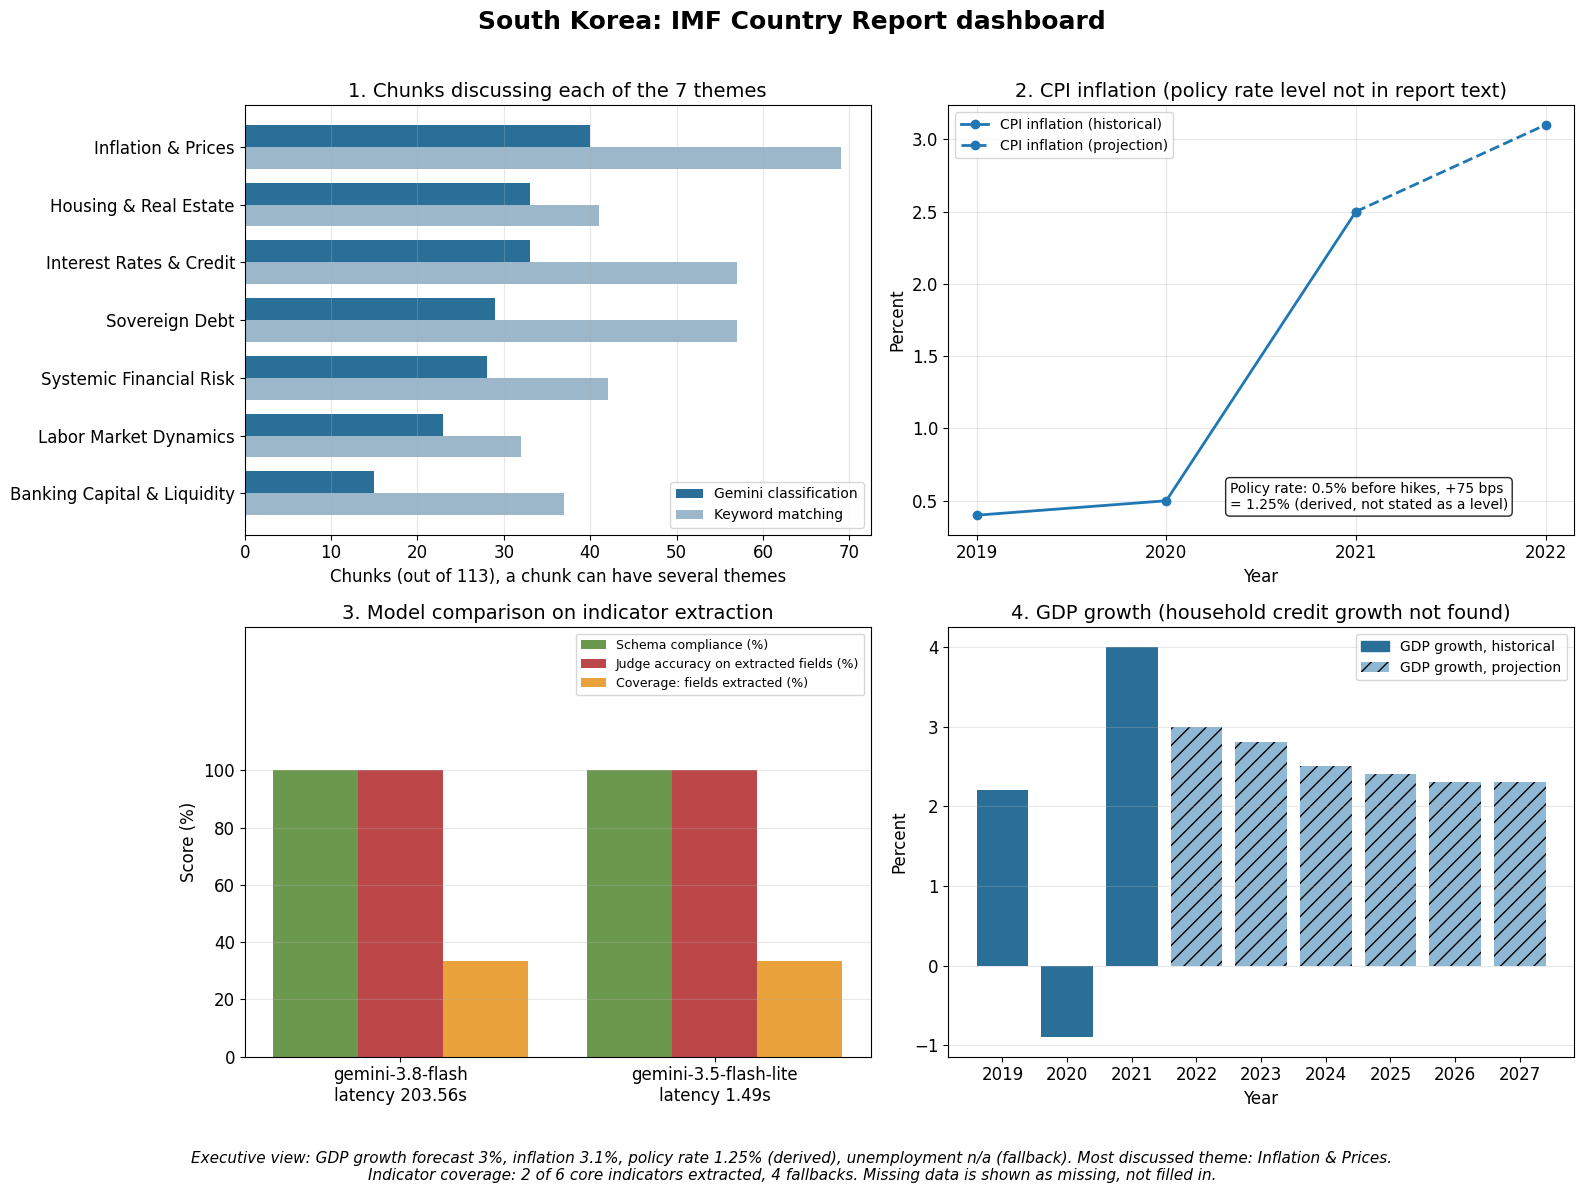

saved dashboard size in pixels: (4800, 3600)


In [21]:
from matplotlib.patches import Patch
plt.rcParams.update({"font.size": 12, "axes.titlesize": 14, "axes.labelsize": 12})
fig, ax = plt.subplots(2, 2, figsize=(16, 12))

# Panel 1: how widely each theme is discussed (chunks), Gemini classification vs keyword matching
order = theme_cmp["semantic_chunks"].sort_values().index
ypos = np.arange(len(order)); h = 0.38
ax[0, 0].barh(ypos + h/2, theme_cmp.loc[order, "semantic_chunks"], h, color="#2a6f97", label="Gemini classification")
ax[0, 0].barh(ypos - h/2, theme_cmp.loc[order, "keyword_chunks"], h, color="#9bb7c9", label="Keyword matching")
ax[0, 0].set_yticks(ypos); ax[0, 0].set_yticklabels(order)
ax[0, 0].set_title("1. Chunks discussing each of the 7 themes")
ax[0, 0].set_xlabel(f"Chunks (out of {len(chunks)}), a chunk can have several themes")
ax[0, 0].grid(axis="x", alpha=0.3); ax[0, 0].legend(loc="lower right", fontsize=10)

# Panel 2: inflation (and policy rate if found), solid = historical, dashed = projection
def plot_series(axis, g, label, color):
    g = g.sort_values("year")
    hist_part = g[g["observation_type"] == "historical"]
    proj_part = pd.concat([hist_part.tail(1), g[g["observation_type"] == "projection"]])
    if len(hist_part):
        axis.plot(hist_part["year"], hist_part["value"], marker="o", linewidth=2, color=color, label=f"{label} (historical)")
    if len(proj_part) > 1 or (len(proj_part) == 1 and not len(hist_part)):
        axis.plot(proj_part["year"], proj_part["value"], marker="o", linewidth=2, linestyle="--", color=color, label=f"{label} (projection)")

ax2 = ax[0, 1]
names = {"inflation_pct": ("CPI inflation", "#1f77b4"), "policy_rate_pct": ("Policy rate", "#d62728")}
plotted = []
for s, (label, color) in names.items():
    g = long_df[long_df["series"] == s]
    if len(g):
        plot_series(ax2, g, label, color)
        plotted.append(s)
ax2.set_title("2. Inflation and policy rate" if len(plotted) == 2 else "2. CPI inflation (policy rate level not in report text)")
ax2.set_xlabel("Year"); ax2.set_ylabel("Percent"); ax2.grid(alpha=0.3)
if derived_policy is not None:
    ax2.text(0.45, 0.06, f"Policy rate: {raw_main['policy_rate_before_hikes_pct']:g}% before hikes, +{raw_main['policy_rate_cumulative_hike_bps']:g} bps\n= {derived_policy:g}% (derived, not stated as a level)",
             transform=ax2.transAxes, fontsize=10, bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
if plotted:
    ax2.set_xticks(sorted(long_df[long_df["series"].isin(plotted)]["year"].astype(int).unique()))
    ax2.legend(fontsize=10, loc="upper left")
else:
    ax2.text(0.5, 0.5, "no yearly data extracted", ha="center", transform=ax2.transAxes)

# Panel 3: model comparison (schema compliance, judge accuracy, coverage)
ax3 = ax[1, 0]
x = np.arange(len(bench_df)); w = 0.27
ax3.bar(x - w, bench_df["schema_compliance"], w, label="Schema compliance (%)", color="#6a994e")
ax3.bar(x, bench_df["judge_accuracy_pct"], w, label="Judge accuracy on extracted fields (%)", color="#bc4749")
ax3.bar(x + w, bench_df["coverage_pct"], w, label="Coverage: fields extracted (%)", color="#e9a23b")
ax3.set_xticks(x)
ax3.set_xticklabels([f"{m}\nlatency {l}s" if s == "ok" else f"{m}\nno result (quota)"
                     for m, l, s in zip(bench_df["model"], bench_df["latency_s"], bench_df["status"])])
ax3.set_ylim(0, 150); ax3.set_yticks(range(0, 101, 20)); ax3.set_title("3. Model comparison on indicator extraction")
ax3.set_ylabel("Score (%)"); ax3.grid(axis="y", alpha=0.3); ax3.legend(loc="upper right", fontsize=9)

# Panel 4: GDP growth by year (hatched = projection), household credit growth if found
ax4 = ax[1, 1]
g = wide.dropna(subset=["gdp_growth_pct"])
handles = []
if len(g):
    labels = g["year"].astype(int).astype(str)
    bars = ax4.bar(labels, g["gdp_growth_pct"], color=["#2a6f97" if t == "historical" else "#8fb8d4" for t in g["observation_type"]])
    for b, t in zip(bars, g["observation_type"]):
        if t == "projection":
            b.set_hatch("//")
    handles += [Patch(color="#2a6f97", label="GDP growth, historical"), Patch(facecolor="#8fb8d4", hatch="//", label="GDP growth, projection")]
cg = wide.dropna(subset=["household_credit_growth_pct"])
if len(cg):
    ax4.plot(cg["year"].astype(int).astype(str), cg["household_credit_growth_pct"], color="#e07a1f", marker="s", linewidth=2, label="Household credit growth (%)")
    handles += ax4.get_legend_handles_labels()[0]
ax4.set_title("4. GDP growth and household credit growth" if len(cg) else "4. GDP growth (household credit growth not found)")
ax4.set_xlabel("Year"); ax4.set_ylabel("Percent"); ax4.grid(axis="y", alpha=0.3)
if handles:
    ax4.legend(handles=handles, fontsize=10)

# executive text overlay built from the extracted numbers
def show(v): return "n/a (fallback)" if v == -1.0 else f"{v:g}%"
policy_text = show(indicators["central_bank_policy_rate_pct"]) if derived_policy is None else f"{derived_policy:g}% (derived)"
n_found = len(NUM_FIELDS) - len(fallbacks)
overlay = (f"Executive view: GDP growth forecast {show(indicators['gdp_growth_forecast_pct'])}, "
           f"inflation {show(indicators['headline_inflation_rate_pct'])}, policy rate {policy_text}, "
           f"unemployment {show(indicators['unemployment_rate_pct'])}. Most discussed theme: {theme_cmp['semantic_chunks'].idxmax()}.\n"
           f"Indicator coverage: {n_found} of {len(NUM_FIELDS)} core indicators extracted, {len(fallbacks)} fallbacks. Missing data is shown as missing, not filled in.")
fig.suptitle("South Korea: IMF Country Report dashboard", fontsize=18, fontweight="bold")
fig.text(0.5, 0.005, overlay, ha="center", fontsize=11, style="italic")
plt.tight_layout(rect=[0, 0.05, 1, 0.97])
plt.savefig(f"{OUT_DIR}/dashboard.png", dpi=300)
plt.show()

from PIL import Image
print("saved dashboard size in pixels:", Image.open(f"{OUT_DIR}/dashboard.png").size)

## 12. Which models answered, then save and download everything

In [22]:
print("calls answered per model:", dict(MODEL_LOG))
save_json({"generator": GEN_MODEL, "judge": JUDGE_MODEL, "calls_per_model": dict(MODEL_LOG),
           "total_summaries": len(sec_df), "section_method": method}, "model_usage.json")

import shutil
shutil.make_archive("/content/outputs_korea", "zip", OUT_DIR)
print(os.listdir(OUT_DIR))
try:
    from google.colab import files
    files.download("/content/outputs_korea.zip")
except Exception:
    pass

calls answered per model: {'gemini-3.8-flash': 22, 'gemini-3.5-flash': 21, 'gemini-3.5-flash-lite': 20}
['summaries.json', 'themes.json', 'insights.json', 'indicators.json', 'trends.json', 'rag_eval.json', 'model_benchmark.json', 'dashboard.png', 'model_usage.json', 'retrieval_eval.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
for m in re.finditer(r"unemployment rate", text_clean, re.I):
    print(text_clean[max(0, m.start()-50):m.end()+150], "\n---")

ggesting some remaining slack. Employment and the unemployment rate are now at their pre-COVID levels, but pockets of labor market weakness remain in high-contact services more exposed to the pandemic and social dista 
---
some remaining labor market slack despite the low unemployment rate. Aggregate job vacancy rates are normalizing, but with wide variation across sectors. Nominal wages have accelerated, though wage gains are moderate  
---
